In [1]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
dti = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
dti = dti[dti.regionname == 'CST_R']
dti = dti[dti.isPatient == 1]

# WMV in CST
wmv = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_WM', 'summary_MNISymC_CST_WM_mod.tsv'), sep = '\t')
wmv = wmv[wmv.isPatient==1] # just patients

wmv['hemisphere'] = wmv.regionname.str[-1]

wmv_wide = wmv.pivot(index = ['subj_id', 'Week', 'region_bilat'], columns = 'hemisphere', values = 'mean')
wmv_wide['right_norm'] = wmv_wide['R']/wmv_wide['L']
wmv_wide = wmv_wide.reset_index()
wmv = wmv_wide.melt(
    id_vars = ['subj_id', 'Week', 'region_bilat'],
    value_vars = ['R', 'L', 'right_norm'],
    var_name = 'metric_wmv', value_name = 'mean_wmv'
)
wmv = wmv[wmv.metric_wmv == 'right_norm']
wmv = wmv.drop(columns = 'metric_wmv')
wmv = wmv.rename(columns = {'mean_wmv': 'right_norm'})

# behavioural metrics
behav = pd.read_csv(os.path.join(gl.baseDir, 'behavioural', 'summary_paretic.dat'), sep = '\t')
behav.rename(columns = {'subj_name': 'subj_id', 'week': 'Week'}, inplace = True)
behav['subj_id'] = behav['subj_id'].str.strip()
behav.loc[behav['Week']==1, 'Week'] = 0


# cerebellum GMV
cerebel = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_GM', 'summary_MNISymC_Nettekoven_2024_GM_mod.tsv'), sep = '\t')
cerebel = cerebel[cerebel.isPatient==1] # just patients

cerebel['hemisphere'] = cerebel.regionname.str[2]
cerebel['regionname_bilat'] = cerebel.regionname.str[:2]

cerebel_wide = cerebel.pivot(index = ['subj_id', 'Week', 'regionname_bilat'], columns = 'hemisphere', values = 'mean')
cerebel_wide['left_norm'] = cerebel_wide['L']/cerebel_wide['R']
cerebel_wide = cerebel_wide.reset_index()
cerebel = cerebel_wide.melt(
    id_vars = ['subj_id', 'Week', 'regionname_bilat'],
    value_vars = ['L', 'R', 'left_norm'],
    var_name = 'metric_cerebel', value_name = 'mean_cerebel'
)
cerebel = cerebel[cerebel.metric_cerebel == 'left_norm']
cerebel = cerebel.drop(columns = 'metric_cerebel')
cerebel = cerebel.rename(columns = {'mean_cerebel': 'left_norm'})


# CST: WMV and FA asymmetry index

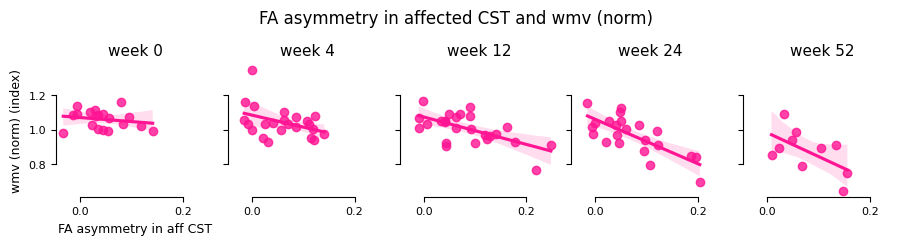

**Pearson R and p-value for FA asymmetry in affected CST and WMV** 

week 0: r = -0.1988914756592231, p-value = 0.4143314164588025
week 4: r = -0.39888468228654017, p-value = 0.05937291248742862
week 12: r = -0.6224211272113682, p-value = 0.00089217360430392
week 24: r = -0.7489085540450113, p-value = 6.070017140307189e-05
week 52: r = -0.5922483046242908, p-value = 0.0712305593513851


In [2]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    wmv_plot = wmv[wmv.Week == week]
    dti_plot = dti[(dti.Week == week)]
    wmv_dti_plot = pd.merge(dti_plot, wmv_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_wmv'))

    ax = axs[i]
    sns.regplot(x = 'asymmetry_index', y = 'right_norm', data = wmv_dti_plot, ax = ax, color = 'deeppink')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("wmv (norm) (index)")
axs[0].set_xlabel(f"FA asymmetry in aff CST")
fig.suptitle(f"FA asymmetry in affected CST and wmv (norm)", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for FA asymmetry in affected CST and WMV** \n")
for week in gl.weeks:
    wmv_plot = wmv[wmv.Week == week]
    dti_plot = dti[(dti.Week == week)]
    wmv_dti_plot = pd.merge(dti_plot, wmv_plot, on = ['subj_id', 'Week'], suffixes = ('_dti', '_wmv'))

    r_stat, p_stat = stats.pearsonr(wmv_dti_plot['asymmetry_index'], wmv_dti_plot['right_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')


# CST WMV and individuation

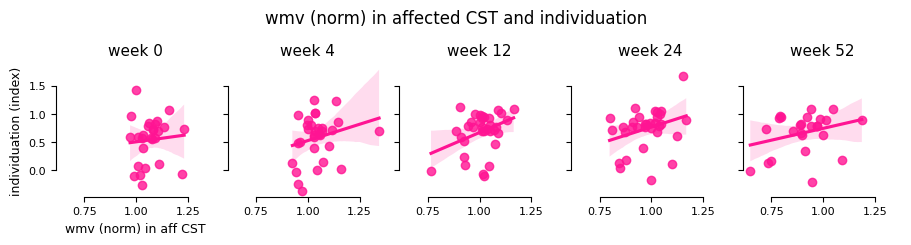

**Pearson R and p-value for wmv (norm) in affected CST and individuation** 

week 0: r = 0.08283603942859794, p-value = 0.681242223497918
week 4: r = 0.2367157647528846, p-value = 0.1997969439650018
week 12: r = 0.3633413973399935, p-value = 0.03467182820216529
week 24: r = 0.30744437839651345, p-value = 0.08694990474158525
week 52: r = 0.29366532349874847, p-value = 0.15421684350568252


In [28]:
fig, axs = plt.subplots(1, 5, figsize = (9,2), sharey = True, sharex = True, constrained_layout = True)
for i, week in enumerate(gl.weeks):
    behav_plot = behav[behav.Week == week]
    wmv_plot = wmv[wmv.Week == week]
    behav_wmv_plot = pd.merge(wmv_plot, behav_plot, on = ['subj_id'], suffixes = ('_wmv', '_behav'))

    ax = axs[i]
    sns.regplot(x = 'right_norm', y = 'indiv_norm', data = behav_wmv_plot, ax = ax, color = 'deeppink')

    ax.set_ylabel('')
    ax.set_xlabel('')

    ax.set_title(f'week {week}')
    

axs[0].set_ylabel("individuation (index)")
axs[0].set_xlabel(f"wmv (norm) in aff CST")
fig.suptitle(f"wmv (norm) in affected CST and individuation", y = 1.15)

sns.despine(trim = True)
plt.show()


print("**Pearson R and p-value for wmv (norm) in affected CST and individuation** \n")
for week in gl.weeks:
    behav_plot = behav[behav.Week == week]
    wmv_plot = wmv[wmv.Week == week]
    behav_wmv_plot = pd.merge(wmv_plot, behav_plot, on = ['subj_id'], suffixes = ('_wmv', '_behav'))

    r_stat, p_stat = stats.pearsonr(behav_wmv_plot['right_norm'], behav_wmv_plot['indiv_norm'])
    print(f'week {week}: r = {r_stat}, p-value = {p_stat}')


what is the time course to see WMV in T1 for Wallerian degeneration??